# Multi-Task Cognitive Prediction: NOFE vs PCA

Compares two dimensionality-reduction strategies as input features for a **multi-task MLP** that predicts all 7 cognitive scores simultaneously.

| Feature | Pipeline |
|---|---|
| **NOFE** | DWI (143-dim) → GNN hidden states (32-dim) → mean-pool per subject |
| **PCA**  | DWI (143-dim) → mean across brain voxels (143-dim) → PCA (32-dim) |

Evaluation: **Leave-One-Out CV** (LOO) over 16 subjects.

In [1]:
import sys, json, gc
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneOut
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe

project_root = Path('../../').resolve()
sys.path.insert(0, str(project_root / 'src'))
sys.path.insert(0, str(project_root / 'dMRI' / 'scripts'))

from utilities import KernelNN
from utilities_dMRI import dMRI_Graph_Generator

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print(f'Device: {device}')

using Device: mps
Device: mps


## 1. Load NOFE Model

In [2]:
model_type   = 'regular'
model_prefix = 'base'

trained_models_path = project_root / 'dMRI' / 'trained_models' / model_type
available = sorted([f.stem for f in trained_models_path.glob(f'{model_prefix}_*.pth')])
if not available:
    raise FileNotFoundError(f'No {model_prefix} model found')
model_id = available[-1]
print(f'Model: {model_id}')

with open(trained_models_path / 'logs' / 'configs' / f'{model_id}.json') as f:
    config = json.load(f)

model = KernelNN(
    width     = config['width'],
    ker_width = config['ker_width'],
    depth     = config['depth'],
    in_width  = config['node_features'],
    ker_in    = config['edge_attr'],
    out_width = config['out_width'],
)
model.load_state_dict(torch.load(
    trained_models_path / f'{model_id}.pth', map_location='cpu'
))
model.eval().to(device)

EMBED_DIM = config['width']   # 32
print(f'Embedding dim: {EMBED_DIM}')

Model: base_2026-04-29_t11-16-23
Embedding dim: 32


## 2. Extract Features for Both Methods

In [3]:
from dipy.reconst.dti import TensorModel
from dipy.core.gradients import gradient_table as dipy_gtab

FA_THRESHOLD = 0.2
REGION_NAMES = ['frontal', 'parietal', 'temporal', 'occipital', 'subcortical']

def region_masks(coords):
    y, z = coords[:, 1], coords[:, 2]
    return {
        'frontal':     y > 0.60,
        'parietal':    (y > 0.35) & (y < 0.85) & (z > 0.62),
        'temporal':    (y > 0.20) & (y < 0.70) & (z < 0.55),
        'occipital':   y < 0.25,
        'subcortical': (y > 0.35) & (y < 0.65) & (z > 0.28) & (z < 0.58),
    }

@torch.no_grad()
def extract_nofe(model, graph):
    x  = graph.x.to(device)
    ei = graph.edge_index.to(device)
    ea = graph.edge_attr.to(device)
    x  = model.fc1(x)
    for _ in range(model.depth):
        x = F.relu(model.conv1(x, ei, ea))
    return x.cpu().numpy()   # (N_voxels, 32)

def compute_fa_mask(da_tensor, bvals, bvecs, b0_threshold=100, fa_thresh=0.2):
    b1000_sel = bvals < 1200
    gtab = dipy_gtab(bvals[b1000_sel], bvecs=bvecs[:, b1000_sel],
                     b0_threshold=b0_threshold)
    data_dti = da_tensor.detach().cpu().numpy()[:, b1000_sel]
    fa = np.clip(TensorModel(gtab).fit(data_dti).fa, 0, 1)
    return torch.from_numpy(fa > fa_thresh)   # bool tensor

def sample_and_extract(generator, n_voxels, n_repeats):
    """Sample N_REPEATS graphs, return mean hidden states and coords per repeat."""
    n_total = generator.da.shape[0]
    n = min(n_voxels, n_total)
    hidden_list, coords_list = [], []
    for _ in range(n_repeats):
        graph    = generator.sample_graph(
            N=n, k=config['k'], perplexity=config['perplexity'],
            sampling_method='random', gen_feature_mode=config['feature_mode'],
            sigma_method=config['sigma_method'],
        )
        hidden_list.append(extract_nofe(model, graph))          # (n, 32)
        coords_list.append(graph.normed_coords.cpu().numpy())   # (n, 3)
    return hidden_list, coords_list

def region_mean(hidden, coords):
    """5-region mean-pool → (160,)"""
    masks = region_masks(coords)
    parts = []
    for rn in REGION_NAMES:
        m = masks[rn]
        parts.append(hidden[m].mean(axis=0) if m.sum() > 0 else np.zeros(EMBED_DIM))
    return np.concatenate(parts)


data_root    = project_root / 'dMRI' / 'data'
DIFF_SUBPATH = 'T1w/Diffusion_7T/'
N_VOXELS     = 10000
N_REPEATS    = 10

local_subjects = sorted([d for d in data_root.iterdir()
                          if d.is_dir() and d.name.isdigit()])
print(f'Subjects: {len(local_subjects)}')

Generator   = dMRI_Graph_Generator(str(data_root))
subject_ids = []

nofe_global_list  = []   # (N, 32)  全脑 mean-pool  ← baseline
nofe_region_list  = []   # (N, 160) 方案1: 脑区
nofe_wm_list      = []   # (N, 32)  方案3: 白质
nofe_wm_reg_list  = []   # (N, 160) 方案1+3
raw_list          = []   # (N, 143) 全脑均值 DWI
raw_wm_list       = []   # (N, 143) 白质均值 DWI

for subj_dir in local_subjects:
    path  = str(subj_dir / DIFF_SUBPATH) + '/'
    bvals = np.loadtxt(path + 'bvals')
    bvecs = np.loadtxt(path + 'bvecs')
    print(f'  {subj_dir.name} — FA ...', end=' ', flush=True)

    Generator.load_data(path=path)
    orig_da     = Generator.da               # (N_brain, 143) CPU tensor
    orig_coords = Generator.normed_coords    # (N_brain, 3)   CPU tensor

    # ── 白质掩膜 ──────────────────────────────────────────────
    wm_bool = compute_fa_mask(orig_da, bvals, bvecs, fa_thresh=FA_THRESHOLD)
    print(f'WM={wm_bool.float().mean()*100:.0f}% — features ...', end=' ', flush=True)

    # PCA 输入
    da_np = orig_da.detach().cpu().numpy()
    raw_list.append(da_np.mean(axis=0))
    raw_wm_list.append(da_np[wm_bool.numpy()].mean(axis=0)
                       if wm_bool.sum() > 0 else da_np.mean(axis=0))

    # ── 全脑采样 → Global + Region (方案1) ────────────────────
    Generator.da            = orig_da
    Generator.normed_coords = orig_coords
    hidden_list, coords_list = sample_and_extract(Generator, N_VOXELS, N_REPEATS)

    global_acc = np.stack([h.mean(axis=0) for h in hidden_list]).mean(axis=0)
    region_acc = np.stack([region_mean(h, c)
                           for h, c in zip(hidden_list, coords_list)]).mean(axis=0)

    # ── 白质采样 → WM + WM×Region (方案3, 方案1+3) ────────────
    Generator.da            = orig_da[wm_bool]
    Generator.normed_coords = orig_coords[wm_bool]
    wm_hidden_list, wm_coords_list = sample_and_extract(Generator, N_VOXELS, N_REPEATS)

    wm_acc     = np.stack([h.mean(axis=0) for h in wm_hidden_list]).mean(axis=0)
    wm_reg_acc = np.stack([region_mean(h, c)
                            for h, c in zip(wm_hidden_list, wm_coords_list)]).mean(axis=0)

    nofe_global_list.append(global_acc)
    nofe_region_list.append(region_acc)
    nofe_wm_list.append(wm_acc)
    nofe_wm_reg_list.append(wm_reg_acc)
    subject_ids.append(int(subj_dir.name))
    print('done')
    gc.collect()

X_nofe        = np.stack(nofe_global_list)   # (N, 32)   baseline
X_nofe_reg    = np.stack(nofe_region_list)   # (N, 160)  方案1
X_nofe_wm     = np.stack(nofe_wm_list)       # (N, 32)   方案3
X_nofe_wm_reg = np.stack(nofe_wm_reg_list)   # (N, 160)  方案1+3
X_raw         = np.stack(raw_list)            # (N, 143)
X_raw_wm      = np.stack(raw_wm_list)         # (N, 143)

print(f'\nNOFE-Global    : {X_nofe.shape}')
print(f'NOFE-Region    : {X_nofe_reg.shape}')
print(f'NOFE-WM        : {X_nofe_wm.shape}')
print(f'NOFE-WM+Region : {X_nofe_wm_reg.shape}')
print(f'Raw full-brain : {X_raw.shape}')
print(f'Raw WM-only    : {X_raw_wm.shape}')

Subjects: 16
  115017 — FA ... 

/Users/siche9897/miniconda3/envs/neural-operators-new/lib/python3.10/site-packages/dipy/reconst/dti.py:1476: RuntimeWarning: divide by zero encountered in matmul
  w = np.exp(fit_result @ design_matrix.T)
/Users/siche9897/miniconda3/envs/neural-operators-new/lib/python3.10/site-packages/dipy/reconst/dti.py:1476: RuntimeWarning: overflow encountered in matmul
  w = np.exp(fit_result @ design_matrix.T)
/Users/siche9897/miniconda3/envs/neural-operators-new/lib/python3.10/site-packages/dipy/reconst/dti.py:1476: RuntimeWarning: invalid value encountered in matmul
  w = np.exp(fit_result @ design_matrix.T)


WM=55% — features ... 

/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torc

done
  115825 — FA ... 

/Users/siche9897/miniconda3/envs/neural-operators-new/lib/python3.10/site-packages/dipy/reconst/dti.py:1476: RuntimeWarning: divide by zero encountered in matmul
  w = np.exp(fit_result @ design_matrix.T)
/Users/siche9897/miniconda3/envs/neural-operators-new/lib/python3.10/site-packages/dipy/reconst/dti.py:1476: RuntimeWarning: overflow encountered in matmul
  w = np.exp(fit_result @ design_matrix.T)
/Users/siche9897/miniconda3/envs/neural-operators-new/lib/python3.10/site-packages/dipy/reconst/dti.py:1476: RuntimeWarning: invalid value encountered in matmul
  w = np.exp(fit_result @ design_matrix.T)


... (56 outputs left out)

WM=55% — features ... 

/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torc

done

NOFE-Global    : (16, 32)
NOFE-Region    : (16, 160)
NOFE-WM        : (16, 32)
NOFE-WM+Region : (16, 160)
Raw full-brain : (16, 143)
Raw WM-only    : (16, 143)


/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)


## 3. PCA Reduction (143 → 32 dims)

Full-brain PCA: 15 components, 100.0% variance explained
WM-only PCA: 15 components, 100.0% variance explained


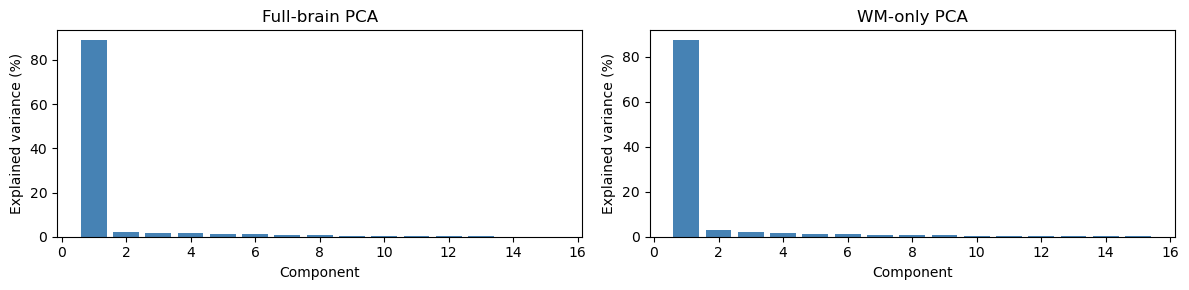

In [4]:
def fit_pca(X, n_components):
    n_pca = min(n_components, len(X) - 1)
    pca = PCA(n_components=n_pca, random_state=0)
    return pca.fit_transform(StandardScaler().fit_transform(X)), pca

X_pca,    pca_full = fit_pca(X_raw,    EMBED_DIM)   # full-brain PCA
X_pca_wm, pca_wm   = fit_pca(X_raw_wm, EMBED_DIM)  # WM-only PCA

for name, pca in [('Full-brain PCA', pca_full), ('WM-only PCA', pca_wm)]:
    ev = pca.explained_variance_ratio_.cumsum()[-1]
    print(f'{name}: {pca.n_components_} components, {ev*100:.1f}% variance explained')

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, pca, title in [(axes[0], pca_full, 'Full-brain PCA'),
                        (axes[1], pca_wm,  'WM-only PCA')]:
    ax.bar(range(1, pca.n_components_ + 1),
           pca.explained_variance_ratio_ * 100, color='steelblue')
    ax.set_xlabel('Component')
    ax.set_ylabel('Explained variance (%)')
    ax.set_title(title)
plt.tight_layout()
plt.show()

## 4. Load Cognitive Scores

In [5]:
csv_path = sorted(data_root.glob('HCP_YA_subjects_*.csv'))[-1]
df = pd.read_csv(csv_path)

TARGETS = {
    'CardSort':  'CardSort_Unadj',
    'Flanker':   'Flanker_Unadj',
    'PMAT24':    'PMAT24_A_CR',
    'ProcSpeed': 'ProcSpeed_Unadj',
    'ListSort':  'ListSort_Unadj',
    'ReadEng':   'ReadEng_Unadj',
    'PicVocab':  'PicVocab_Unadj',
}
TARGET_NAMES = list(TARGETS.keys())
N_TARGETS    = len(TARGET_NAMES)

local_df = df[df['Subject'].isin(subject_ids)].set_index('Subject')
Y = np.stack([
    local_df.loc[subject_ids, col].values.astype(float)
    for col in TARGETS.values()
], axis=1)   # (N_subj, 7)

print(f'Y shape: {Y.shape}')
for i, name in enumerate(TARGET_NAMES):
    print(f'  {name:12s}: mean={Y[:,i].mean():.1f}  std={Y[:,i].std():.1f}')

Y shape: (16, 7)
  CardSort    : mean=114.4  std=11.4
  Flanker     : mean=109.3  std=7.5
  PMAT24      : mean=14.1  std=5.3
  ProcSpeed   : mean=115.5  std=17.9
  ListSort    : mean=109.3  std=12.2
  ReadEng     : mean=118.2  std=12.1
  PicVocab    : mean=113.9  std=10.1


## 5. Multi-Task MLP + LOO-CV

In [6]:
class MultiTaskMLP(nn.Module):
    def __init__(self, in_dim, n_targets, hidden=64, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.BatchNorm1d(hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden // 2), nn.ReLU(),
            nn.Linear(hidden // 2, n_targets),
        )
    def forward(self, x):
        return self.net(x)

def loo_multitask(X, Y, epochs=2000, lr=5e-4, hidden=64, dropout=0.3):
    N, n_targets = Y.shape
    y_true_all = np.zeros_like(Y); y_pred_all = np.zeros_like(Y)
    for train_idx, test_idx in LeaveOneOut().split(X):
        Xtr, Xte = X[train_idx], X[test_idx]
        Ytr, Yte = Y[train_idx], Y[test_idx]
        sx = StandardScaler().fit(Xtr); sy = StandardScaler().fit(Ytr)
        Xtr_t = torch.tensor(sx.transform(Xtr), dtype=torch.float32)
        Ytr_t = torch.tensor(sy.transform(Ytr), dtype=torch.float32)
        Xte_t = torch.tensor(sx.transform(Xte), dtype=torch.float32)
        net = MultiTaskMLP(X.shape[1], n_targets, hidden=hidden, dropout=dropout)
        opt = Adam(net.parameters(), lr=lr, weight_decay=1e-3)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
        best_loss, best_state, patience = float('inf'), None, 200
        stale = 0
        for ep in range(epochs):
            net.train(); opt.zero_grad()
            loss = F.mse_loss(net(Xtr_t), Ytr_t)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(), max_norm=1.0)
            opt.step(); scheduler.step()
            if loss.item() < best_loss:
                best_loss = loss.item()
                best_state = {k: v.clone() for k, v in net.state_dict().items()}
                stale = 0
            else:
                stale += 1
                if stale >= patience:
                    break
        net.load_state_dict(best_state)
        net.eval()
        with torch.no_grad():
            pred_std = net(Xte_t).numpy()
            pred_std = np.clip(pred_std, -5, 5)   # guard against explosion
            pred = sy.inverse_transform(pred_std)
        y_true_all[test_idx] = Yte; y_pred_all[test_idx] = pred
    return y_true_all, y_pred_all

def mae_per_target(yt, yp):  return np.abs(yt - yp).mean(axis=0)
def rmse_per_target(yt, yp): return np.sqrt(((yt - yp)**2).mean(axis=0))

# 所有方法
FEATURE_SETS = {
    'NOFE-Global':    X_nofe,        # baseline: global mean-pool
    'NOFE-Region':    X_nofe_reg,    # 方案1: 5 脑区
    'NOFE-WM':        X_nofe_wm,     # 方案3: 白质掩膜
    'NOFE-WM+Region': X_nofe_wm_reg, # 方案1+3: 白质 × 脑区
    'PCA-FullBrain':  X_pca,         # PCA baseline
    'PCA-WM':         X_pca_wm,      # PCA 白质
}

loo_results = {}
for name, X in FEATURE_SETS.items():
    print(f'LOO-CV: {name} ({X.shape[1]}dim) ...', end=' ', flush=True)
    yt, yp = loo_multitask(X, Y)
    loo_results[name] = (yt, yp, mae_per_target(yt, yp), rmse_per_target(yt, yp))
    print(f'mean-MAE={loo_results[name][2].mean():.2f}')

print(f'\n{"Score":12s}', '  '.join(f'{n:>14s}' for n in FEATURE_SETS))
print('-' * (12 + 16 * len(FEATURE_SETS)))
for i, t in enumerate(TARGET_NAMES):
    row = f'{t:12s}'
    maes = [loo_results[n][2][i] for n in FEATURE_SETS]
    best = min(maes)
    for v in maes:
        mark = ' ★' if v == best else '  '
        row += f'  {v:>12.2f}{mark}'
    print(row)

LOO-CV: NOFE-Global (32dim) ... mean-MAE=24.77
LOO-CV: NOFE-Region (160dim) ... mean-MAE=26.80
LOO-CV: NOFE-WM (32dim) ... mean-MAE=16.05
LOO-CV: NOFE-WM+Region (160dim) ... mean-MAE=15.31
LOO-CV: PCA-FullBrain (15dim) ... mean-MAE=10.55
LOO-CV: PCA-WM (15dim) ... mean-MAE=9.76

Score           NOFE-Global     NOFE-Region         NOFE-WM  NOFE-WM+Region   PCA-FullBrain          PCA-WM
------------------------------------------------------------------------------------------------------------
CardSort             23.04           21.97           16.84           18.41           10.97            9.61 ★
Flanker              15.94           16.31            9.67            9.11            6.68 ★          7.54  
PMAT24               14.80           14.48            8.38            7.48            5.80            5.78 ★
ProcSpeed            34.48           36.06           23.22           23.81           19.07           14.92 ★
ListSort             35.26           42.85           17.73         

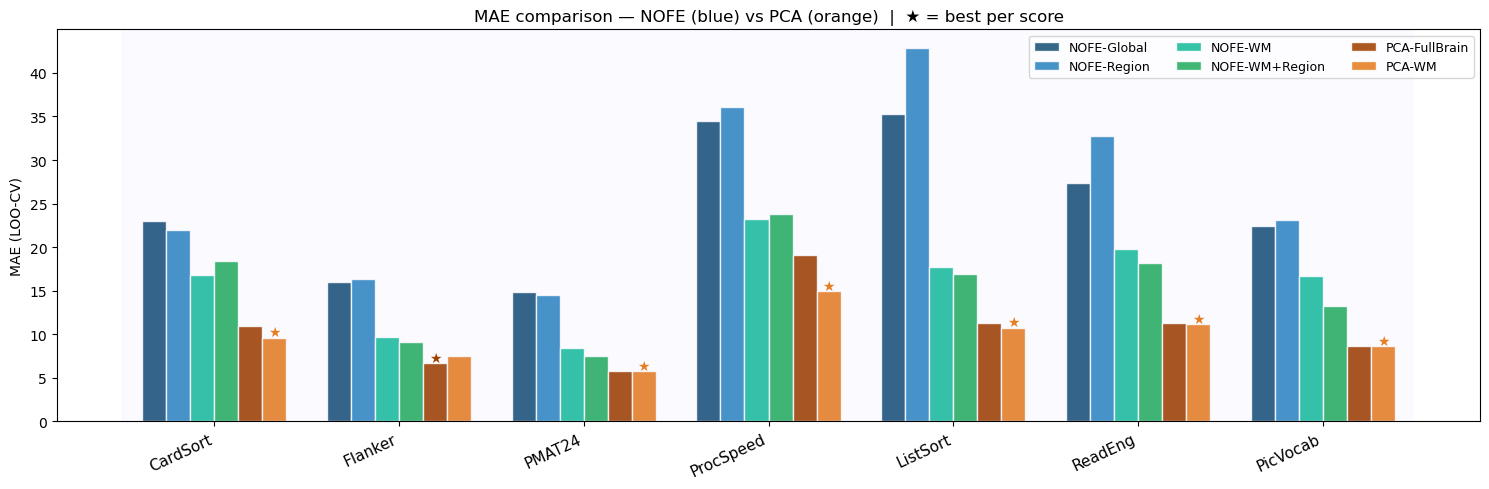

/var/folders/px/747r5b694x947qk1vdh9b3th0000gp/T/ipykernel_27317/928391176.py:61: UserWarning: Glyph 19978 (\N{CJK UNIFIED IDEOGRAPH-4E0A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/px/747r5b694x947qk1vdh9b3th0000gp/T/ipykernel_27317/928391176.py:61: UserWarning: Glyph 19979 (\N{CJK UNIFIED IDEOGRAPH-4E0B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/siche9897/miniconda3/envs/neural-operators-new/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 19978 (\N{CJK UNIFIED IDEOGRAPH-4E0A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/siche9897/miniconda3/envs/neural-operators-new/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 19979 (\N{CJK UNIFIED IDEOGRAPH-4E0B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


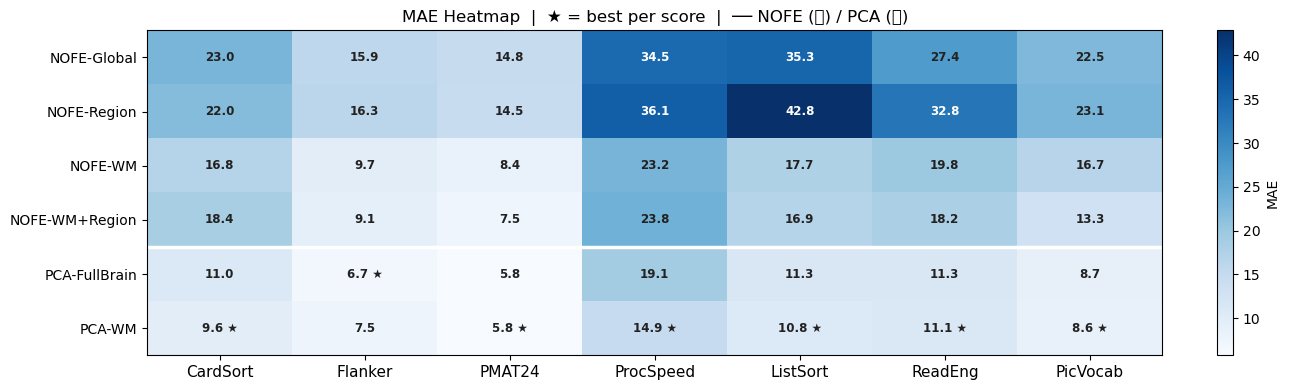

In [7]:
METHOD_COLORS = {
    'NOFE-Global':    '#1A5276',
    'NOFE-Region':    '#2E86C1',
    'NOFE-WM':        '#1ABC9C',
    'NOFE-WM+Region': '#27AE60',
    'PCA-FullBrain':  '#A04000',
    'PCA-WM':         '#E67E22',
}

mae_matrix = np.stack([loo_results[n][2] for n in FEATURE_SETS])  # (6, 7)
x = np.arange(N_TARGETS)
w = 0.13

# ── Bar chart ─────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(15, 5))
for k, (name, color) in enumerate(METHOD_COLORS.items()):
    offset = (k - (len(FEATURE_SETS) - 1) / 2) * w
    ax.bar(x + offset, loo_results[name][2], w,
           label=name, color=color, alpha=0.88, edgecolor='white')

# 每个分数标最优
best_idx = mae_matrix.argmin(axis=0)
names_list  = list(FEATURE_SETS.keys())
colors_list = list(METHOD_COLORS.values())
for j, bi in enumerate(best_idx):
    offset = (bi - (len(FEATURE_SETS) - 1) / 2) * w
    ax.text(j + offset, mae_matrix[bi, j] + 0.15, '★',
            ha='center', fontsize=10, color=colors_list[bi])

ax.set_xticks(x)
ax.set_xticklabels(TARGET_NAMES, rotation=25, ha='right', fontsize=11)
ax.set_ylabel('MAE (LOO-CV)')
ax.set_title('MAE comparison — NOFE (blue) vs PCA (orange)  |  ★ = best per score', fontsize=12)
ax.legend(ncol=3, fontsize=9, loc='upper right')
ax.axvline(x[-1] + 0.5, color='white')  # separator

# 分组背景
ax.axvspan(-0.5, N_TARGETS - 0.5, alpha=0.02, color='blue')
plt.tight_layout()
plt.show()

# ── Heatmap ───────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(13, 4))
im = ax.imshow(mae_matrix, aspect='auto', cmap='Blues',
               vmin=mae_matrix.min(), vmax=mae_matrix.max())
ax.set_xticks(range(N_TARGETS))
ax.set_xticklabels(TARGET_NAMES, fontsize=11)
ax.set_yticks(range(len(FEATURE_SETS)))
ax.set_yticklabels(list(FEATURE_SETS.keys()), fontsize=10)
for i in range(len(FEATURE_SETS)):
    for j in range(N_TARGETS):
        v = mae_matrix[i, j]
        norm_v = (v - mae_matrix.min()) / (mae_matrix.max() - mae_matrix.min() + 1e-9)
        star = ' ★' if mae_matrix[:, j].argmin() == i else ''
        ax.text(j, i, f'{v:.1f}{star}', ha='center', va='center', fontsize=8.5,
                color='white' if norm_v > 0.6 else '#222222', fontweight='bold')
plt.colorbar(im, ax=ax, fraction=0.015, label='MAE')
# 白线分隔 NOFE / PCA 组
ax.axhline(3.5, color='white', lw=2.5)
ax.set_title('MAE Heatmap  |  ★ = best per score  |  ── NOFE (上) / PCA (下)', fontsize=12)
plt.tight_layout()
plt.show()

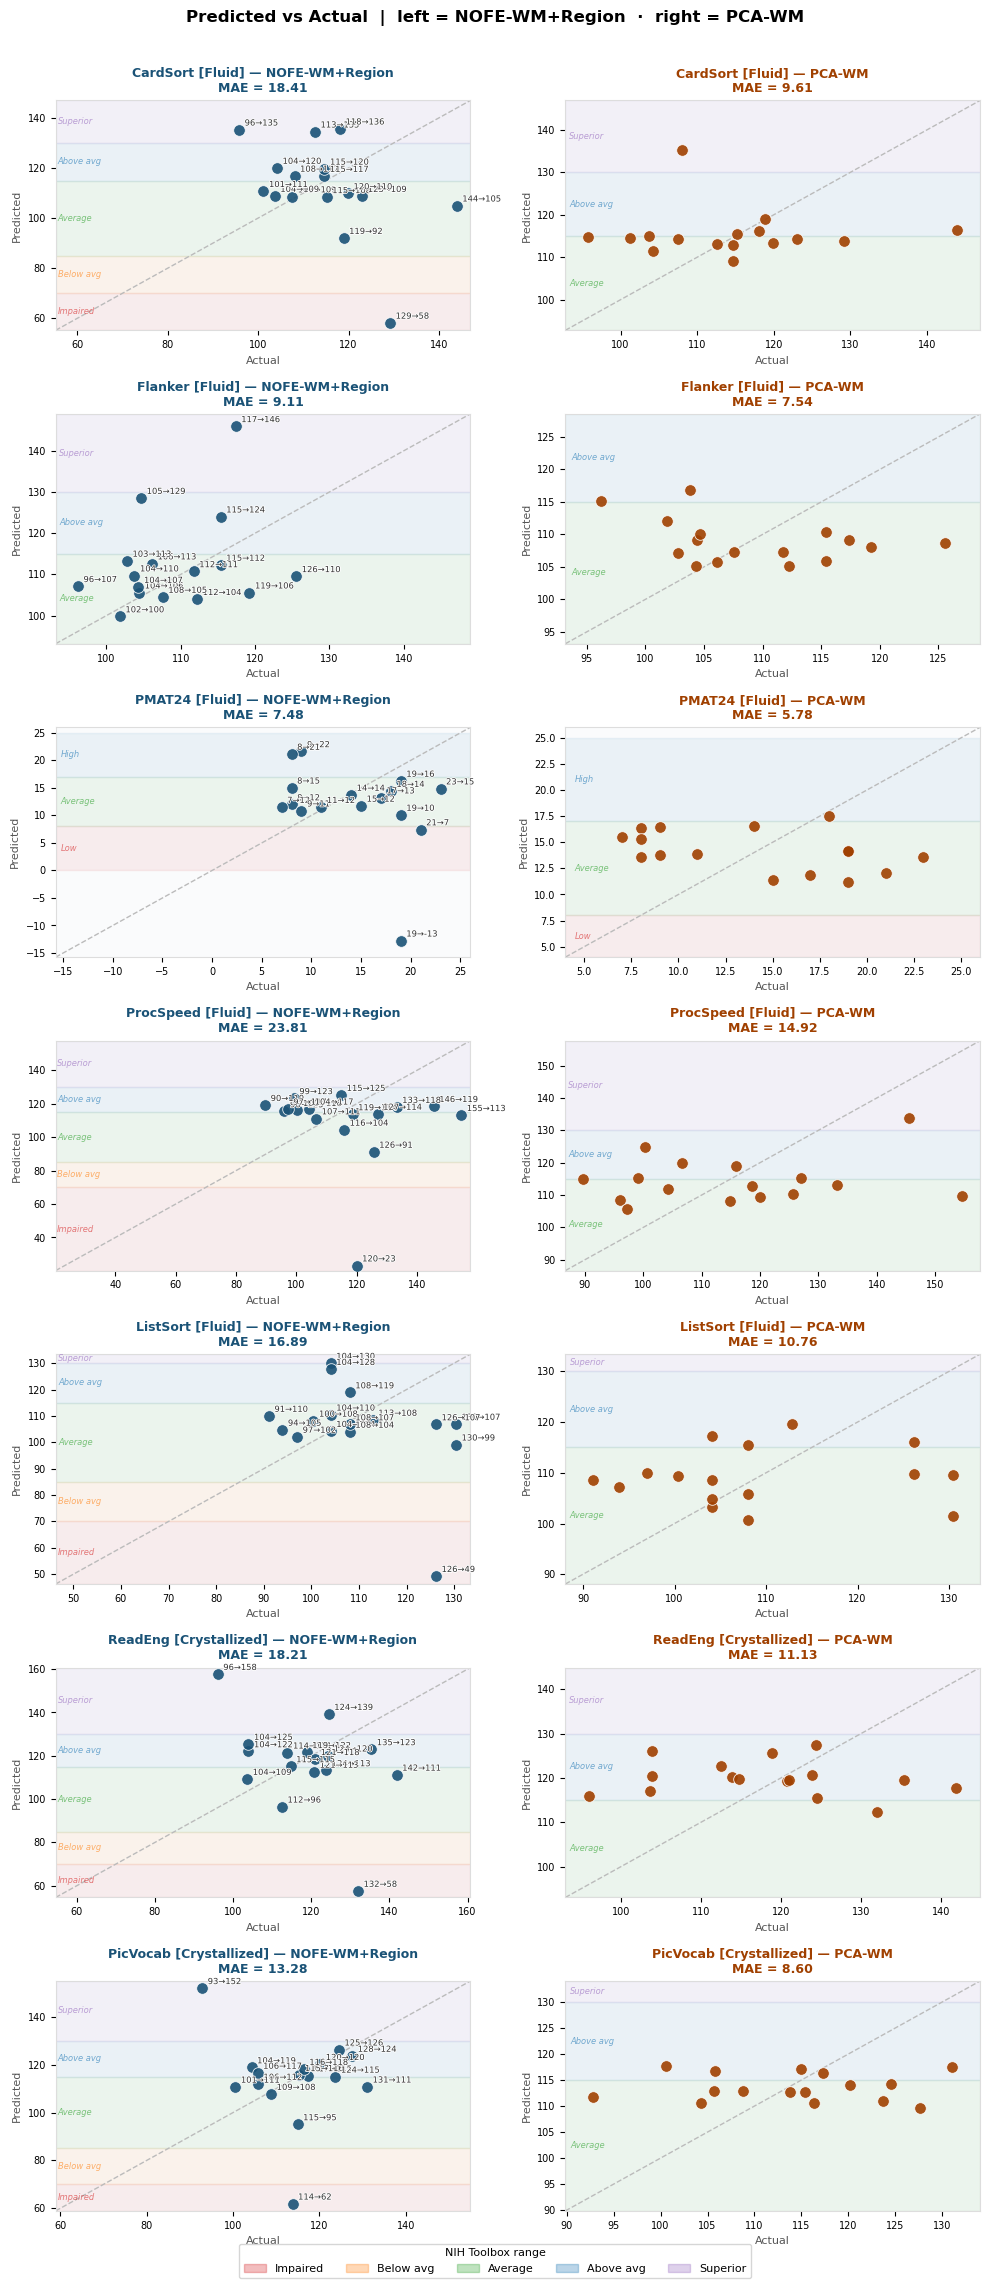

In [8]:
# Scatter: best NOFE method vs best PCA method
BEST_NOFE = 'NOFE-WM+Region'
BEST_PCA  = 'PCA-WM'

nofe_true, nofe_pred = loo_results[BEST_NOFE][0], loo_results[BEST_NOFE][1]
pca_true,  pca_pred  = loo_results[BEST_PCA][0],  loo_results[BEST_PCA][1]

FLUID_TARGETS = {'CardSort', 'Flanker', 'PMAT24', 'ProcSpeed', 'ListSort'}
COLORS = {'NOFE': '#1A5276', 'PCA': '#A04000'}

GRADES = {
    'NIH':  [(0,70,'Impaired','#d62728'),(70,85,'Below avg','#ff7f0e'),
             (85,115,'Average','#2ca02c'),(115,130,'Above avg','#1f77b4'),(130,200,'Superior','#9467bd')],
    'PMAT': [(0,8,'Low','#d62728'),(8,17,'Average','#2ca02c'),(17,25,'High','#1f77b4')],
}
STYPE = {n: ('PMAT' if n == 'PMAT24' else 'NIH') for n in TARGET_NAMES}

fig, axes = plt.subplots(N_TARGETS, 2,
                          figsize=(10, N_TARGETS * 3.2),
                          facecolor='white')

for row, name in enumerate(TARGET_NAMES):
    for col, (label, y_true, y_pred) in enumerate([
        (BEST_NOFE, nofe_true[:, row], nofe_pred[:, row]),
        (BEST_PCA,  pca_true[:,  row], pca_pred[:,  row]),
    ]):
        ax     = axes[row, col]
        color  = COLORS['NOFE'] if col == 0 else COLORS['PCA']
        grades = GRADES[STYPE[name]]
        lo = min(y_true.min(), y_pred.min()) - 3
        hi = max(y_true.max(), y_pred.max()) + 3

        ax.set_facecolor('#fafbfc')
        for g_lo, g_hi, g_lbl, g_col in grades:
            blo, bhi = max(g_lo, lo), min(g_hi, hi)
            if blo < bhi:
                ax.axhspan(blo, bhi, alpha=0.07, color=g_col, zorder=0)
                mid = (blo + bhi) / 2
                if lo < mid < hi:
                    ax.text(lo + 0.5, mid, g_lbl, fontsize=6, color=g_col,
                            va='center', alpha=0.6, style='italic')

        ax.plot([lo, hi], [lo, hi], color='#bbbbbb', lw=1, ls='--', zorder=1)
        ax.scatter(y_true, y_pred, s=70, color=color,
                   edgecolors='white', linewidths=0.6, zorder=3, alpha=0.9)

        if col == 0:
            for xt, xp in zip(y_true, y_pred):
                ax.annotate(f'{xt:.0f}→{xp:.0f}', (xt, xp),
                            textcoords='offset points', xytext=(4, 3),
                            fontsize=6, color='#333333',
                            path_effects=[pe.withStroke(linewidth=1.2, foreground='white')])

        mae_val = np.abs(y_true - y_pred).mean()
        group   = 'Fluid' if name in FLUID_TARGETS else 'Crystallized'
        ax.set_title(f'{name} [{group}] — {label}\nMAE = {mae_val:.2f}',
                     fontsize=9, color=color, fontweight='bold')
        ax.set_xlabel('Actual', fontsize=8, color='#555')
        ax.set_ylabel('Predicted', fontsize=8, color='#555')
        ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
        ax.tick_params(labelsize=7)
        for sp in ax.spines.values(): sp.set_edgecolor('#dddddd')

grade_patches = [mpatches.Patch(color=c, alpha=0.3, label=l)
                 for _, _, l, c in GRADES['NIH']]
fig.legend(handles=grade_patches, title='NIH Toolbox range',
           loc='lower center', ncol=5, fontsize=8,
           title_fontsize=8, bbox_to_anchor=(0.5, -0.01))
fig.suptitle(f'Predicted vs Actual  |  left = {BEST_NOFE}  ·  right = {BEST_PCA}',
             fontsize=12, fontweight='bold', y=1.005)
plt.tight_layout()
plt.show()

## 7. Summary Table

In [9]:
rows = []
for i, name in enumerate(TARGET_NAMES):
    for method_name in FEATURE_SETS:
        yt, yp, mae_arr, rmse_arr = loo_results[method_name]
        pairs = '  '.join(f'{a:.0f}→{p:.0f}' for a, p in zip(yt[:, i], yp[:, i]))
        rows.append({
            'Score':            name,
            'Method':           method_name,
            'MAE':              round(float(mae_arr[i]), 2),
            'RMSE':             round(float(rmse_arr[i]), 2),
            'Actual→Predicted': pairs,
        })

pd.DataFrame(rows)

,Score,Method,MAE,RMSE,Actual→Predicted
0,CardSort,NOFE-Global,23.04,34.25,108→133 96→169 129→58 113→102 115→107 108...
1,CardSort,NOFE-Region,21.97,30.36,108→124 96→63 129→58 113→118 115→109 108→...
2,CardSort,NOFE-WM,16.84,26.47,108→112 96→119 129→68 113→116 115→101 108...
3,CardSort,NOFE-WM+Region,18.41,25.57,108→109 96→135 129→58 113→135 115→108 108...
4,CardSort,PCA-FullBrain,10.97,14.23,108→112 96→118 129→113 113→117 115→118 10...
5,CardSort,PCA-WM,9.61,12.92,108→114 96→115 129→114 113→113 115→116 10...
6,Flanker,NOFE-Global,15.94,21.88,104→132 112→71 117→146 115→105 104→98 104...
7,Flanker,NOFE-Region,16.31,22.98,104→120 112→71 117→146 115→117 104→102 10...
8,Flanker,NOFE-WM,9.67,14.73,104→105 112→122 117→116 115→113 104→101 1...
9,Flanker,NOFE-WM+Region,9.11,12.02,104→106 112→104 117→146 115→124 104→107 1...
